# Modul evaluation
## mse, r2 and extra techniques

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("messy_food_waste_cleaned.csv")

## features corr with target

In [10]:
from sklearn.linear_model import LinearRegression

features = [
    "meals_served",
    "kitchen_staff",
    "temperature_C",
    "humidity_percent",
    "past_waste_kg",
    # "staff_experience"
]

for x in features:
    X = df[[x]]
    y = df["food_waste_kg"]

    model = LinearRegression().fit(X, y)
    print(
        x,
        "coef =", round(model.coef_[0], 2),
        "R² =", round(model.score(X, y), 3)
    )

meals_served coef = 0.06 R² = 0.224
kitchen_staff coef = 0.07 R² = 0.0
temperature_C coef = 0.1 R² = 0.003
humidity_percent coef = 0.1 R² = 0.02
past_waste_kg coef = 0.55 R² = 0.272


## evaluation/metrics, task 2

In [11]:
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             median_absolute_error, mean_absolute_percentage_error, r2_score)

from sklearn.model_selection import train_test_split

# test/train split
X = df[features]
y = df["food_waste_kg"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# model trainning
model = LinearRegression().fit(X_train, y_train)

# predict
pred = model.predict(X_test)

# evaluate
print("mae =", mean_absolute_error(y_test, pred))
print("mse =", mean_squared_error(y_test, pred))
print("mar = ", median_absolute_error(y_test, pred))
print("mape = ", mean_absolute_percentage_error(y_test, pred))
print("r2 =", r2_score(y_test, pred))

mae = 4.92087863328685
mse = 37.86816465788944
mar =  4.070286346216296
mape =  0.12264199408925228
r2 = 0.4678296326945801


## func of evaluation

In [24]:
def evaluate(y_test, pred):
    return {
        "mae": mean_absolute_error(y_test, pred),
        "mse": mean_squared_error(y_test, pred),
        "medAE: ": median_absolute_error(y_test, pred),
        "mape": mean_absolute_percentage_error(y_test, pred),
        "r2": r2_score(y_test, pred)
    }

metrics = evaluate(y_test, pred)
print(metrics)

{'mae': 4.92087863328685, 'mse': 37.86816465788944, 'mar: ': 4.070286346216296, 'mape': 0.12264199408925228, 'r2': 0.4678296326945801}
0.4961191838522653


### 10 observations where model made the biggest errors.

In [15]:
# calculate errors
error = np.abs(y_test - pred)

# create table with them
result = X_test.copy()
result["actual"] = y_test
result["predicted"] = pred
result["error"] = error

# top 10 errors
top10 = result.sort_values(ascending=False, by="error").head(10)
print(top10)

      meals_served  kitchen_staff  temperature_C  humidity_percent  \
1369           260             11          23.81             44.14   
261            285              7          14.86             68.77   
622            263             10          21.35             46.66   
989            263              7          24.01             71.81   
582            148              6          27.56             62.70   
259            261             11          23.91             48.72   
875            216              6          24.58             58.06   
1112           282              8          21.28             48.44   
994            261              9          25.02             66.56   
316            350             10          21.82             59.07   

      past_waste_kg  actual  predicted      error  
1369          30.74   23.80  40.279355  16.479355  
261           39.48   63.12  47.713632  15.406368  
622           32.40   26.05  41.340341  15.290341  
989           47.24  

In [17]:
print(top10[features].describe())
print(top10[["actual", "predicted", "error"]])

       meals_served  kitchen_staff  temperature_C  humidity_percent  \
count     10.000000       10.00000      10.000000         10.000000   
mean     258.900000        8.50000      22.820000         57.493000   
std       51.312658        1.95789       3.381052          9.993652   
min      148.000000        6.00000      14.860000         44.140000   
25%      260.250000        7.00000      21.467500         48.510000   
50%      262.000000        8.50000      23.860000         58.565000   
75%      277.250000       10.00000      24.437500         65.595000   
max      350.000000       11.00000      27.560000         71.810000   

       past_waste_kg  
count      10.000000  
mean       34.767000  
std         5.439393  
min        30.130000  
25%        30.740000  
50%        32.570000  
75%        37.070000  
max        47.240000  
      actual  predicted      error
1369   23.80  40.279355  16.479355
261    63.12  47.713632  15.406368
622    26.05  41.340341  15.290341
989    36.57 

### observation of errors

In [19]:
top10["signed_error"] = top10["predicted"] - top10["actual"]

print(top10[["actual", "predicted", "signed_error", "error"]])

# so if the actual value is 20-36 gacha bosa kopro predict qilayapti
# if actual value is 50+ bosa kamroq predict qilayapti

      actual  predicted  signed_error      error
1369   23.80  40.279355     16.479355  16.479355
261    63.12  47.713632    -15.406368  15.406368
622    26.05  41.340341     15.290341  15.290341
989    36.57  51.715319     15.145319  15.145319
582    53.86  38.818428    -15.041572  15.041572
259    27.27  41.811588     14.541588  14.541588
875    52.94  38.787373    -14.152627  14.152627
1112   27.77  41.672369     13.902369  13.902369
994    59.12  45.964715    -13.155285  13.155285
316    58.83  46.436316    -12.393684  12.393684


In [22]:
# compare top errors with full dataset
print(top10[features].mean())
print(X_test[features].mean())
# they are almost the same

# Check whether these errors are unusually large
print("Top 10 mean error:", top10["error"].mean())
print("Overall mean error:", error.mean())
print("Maximum error:", error.max())
# max = 16, mean = 14 almost the same so nothing unusual

meals_served        258.900
kitchen_staff         8.500
temperature_C        22.820
humidity_percent     57.493
past_waste_kg        34.767
dtype: float64
meals_served        250.080986
kitchen_staff         8.140845
temperature_C        22.893627
humidity_percent     59.127007
past_waste_kg        31.456197
dtype: float64
Top 10 mean error: 14.550850737493658
Overall mean error: 4.92087863328685
Maximum error: 16.47935473013536


### r2_adjusted

In [25]:
# add ajusted r2 func
def adjusted_r2(r2, n, k):
    return 1 - (1 - r2) * (n - 1) / (n - k - 1)

print(adjusted_r2(model.score(X, y), len(X), X.shape[1])) # 0.4961191838522653 eskisi 0.4678296326945801 rostanam oshdi

0.4961191838522653


### analyzing remainders

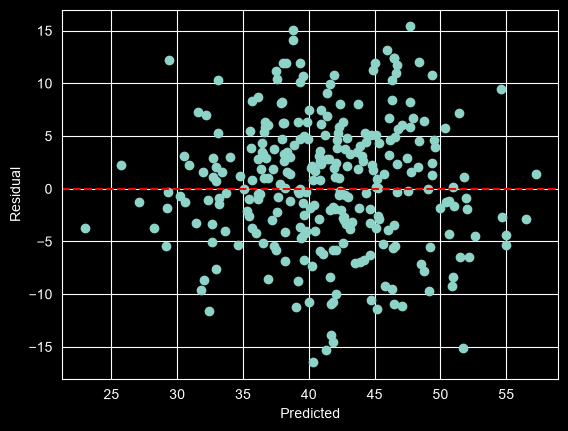

In [27]:
resid = y_test - pred
plt.scatter(pred, resid)
plt.axhline(0, color="r", linestyle="--")
plt.xlabel("Predicted")
plt.ylabel("Residual")
plt.show()
# the residual plot as showing a generally random scatter around zero, with some relatively large prediction errors and no obvious nonlinear pattern.

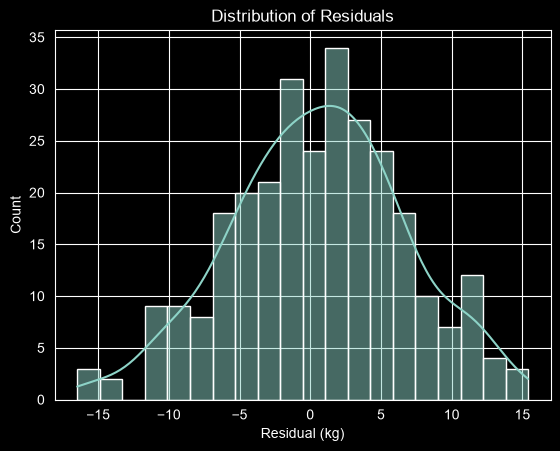

Mean: 0.5499141292921155
Std: 6.139910447763619


In [30]:
# residual hist plot
sns.histplot(resid, bins=20, kde=True)
plt.xlabel("Residual (kg)")
plt.title("Distribution of Residuals")
plt.show()

print("Mean:", resid.mean())
print("Std:", resid.std())

In [31]:
results = pd.DataFrame({
    "predicted": pred,
    "residual": resid
}, index=y_test.index)

results["group"] = pd.qcut(
    results["predicted"],
    q=3,
    labels=["Low", "Medium", "High"]
)

group_stats = results.groupby(
    "group", observed=True
)["residual"].agg(["mean", "std", "count"])

print(group_stats)

            mean       std  count
group                            
Low     1.379629  5.376084     95
Medium -0.381823  6.222779     94
High    0.642129  6.686610     95


# Other not completed tasks

In [32]:
# Original evaluation
original_metrics = evaluate(y_test, pred)

# Create a copy and select five observations
y_test_outliers = y_test.copy()
outlier_indices = y_test_outliers.nlargest(5).index

# Artificially multiply their actual food-waste values by 10
y_test_outliers.loc[outlier_indices] *= 10

# Evaluate using the same predictions
outlier_metrics = evaluate(y_test_outliers, pred)

comparison = pd.DataFrame({
    "Original": original_metrics,
    "With Outliers": outlier_metrics
})

comparison["Difference"] = (
    comparison["With Outliers"] - comparison["Original"]
)

display(comparison.round(3))

# After introducing five extreme target values, MAE changed from [4.921] to [14.645], while RMSE changed from [37.868] to [5650.690]. RMSE is particularly sensitive to large errors because it squares residuals, whereas MedAE is generally more robust to a small number of extreme observations. R² also changed because the relationship between predictions and actual values was affected by the outliers

,Original,With Outliers,Change
mae,4.921,14.645,9.724
mse,37.868,5650.690,5612.822
mar:,4.070,4.070,0.000
mape,0.123,0.135,0.013
r2,0.468,0.014,-0.454


Dataset A R²: 0.9312
Dataset B R²: 0.831
R² difference: 0.1002


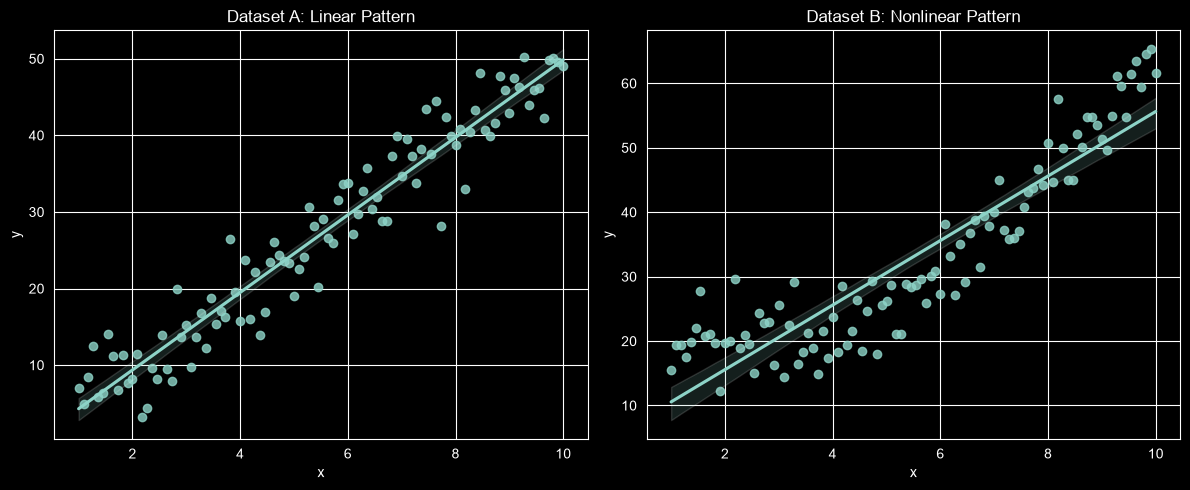

In [33]:
np.random.seed(42)

# Dataset A: approximately linear relationship
x_a = np.linspace(1, 10, 100)
y_a = 5 * x_a + np.random.normal(0, 4, 100)

# Dataset B: nonlinear relationship
x_b = np.linspace(1, 10, 100)
y_b = 5 * x_b + 0.8 * (x_b - 5.5) ** 2
y_b += np.random.normal(0, 4, 100)

def get_r2(x, y):
    model = LinearRegression()
    model.fit(x.reshape(-1, 1), y)
    return model.score(x.reshape(-1, 1), y)

# Adjust the nonlinear dataset's noise scale to get similar R²
# Both datasets retain different underlying shapes
for noise_scale in np.linspace(1, 15, 1000):
    np.random.seed(42)
    candidate_y = (
        5 * x_b
        + 0.8 * (x_b - 5.5) ** 2
        + np.random.normal(0, noise_scale, len(x_b))
    )

    if abs(get_r2(x_a, y_a) - get_r2(x_b, candidate_y)) < 0.01:
        y_b = candidate_y
        break

df_a = pd.DataFrame({"x": x_a, "y": y_a, "dataset": "A - Linear"})
df_b = pd.DataFrame({"x": x_b, "y": y_b, "dataset": "B - Nonlinear"})

df_anscombe = pd.concat([df_a, df_b], ignore_index=True)

print("Dataset A R²:", round(get_r2(x_a, y_a), 4))
print("Dataset B R²:", round(get_r2(x_b, y_b), 4))
print("R² difference:", round(abs(get_r2(x_a, y_a) - get_r2(x_b, y_b)), 4))

# Plot both datasets
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.regplot(x=x_a, y=y_a, ax=axes[0])
axes[0].set_title("Dataset A: Linear Pattern")
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")

sns.regplot(x=x_b, y=y_b, ax=axes[1])
axes[1].set_title("Dataset B: Nonlinear Pattern")
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")

plt.tight_layout()
plt.show()